# 05 · Exploration: weather, activity and tariffs (course period)

Notebooks 02–03 suggest the models lacked information, not capacity. Here the target becomes the **year-over-year change** log(demand / same month last year) — the seasonal rule is "change = 0" — and three drivers are added:

- **weather**: heating and cooling degree-days of the month minus those of the same month last year;
- **activity**: EMAE year-over-year change;
- **tariffs**: year-over-year change of the real utilities price.

⚠️ This uses the course test months, which had already been looked at. It motivates notebook 06 but is not evidence by itself.

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cammesa.plots import style, BLUE, ORANGE, AQUA, YELLOW, RULE, INK2, MUTED
style(); pd.set_option('display.precision', 1); pd.set_option('display.width', 160)
FIG = '../docs/figures/'

In [2]:
from cammesa import exploratory as x
e = x.yoy_experiments()
e

,model,validation RMSE,test RMSE,known in advance
0,Seasonal rule (change = 0),128.4,71.0,True
1,Last month's change only,114.2,68.4,True
2,+ weather of the month,56.0,40.1,False
3,"+ weather of the month, per region",60.1,41.5,False
4,+ weather per region + EMAE of the month,53.5,37.9,False
5,+ weather per region + EMAE as published (t-2),58.6,44.7,False
6,+ normal weather (known in advance),95.9,87.4,True
7,+ normal weather + EMAE as published (t-2),86.5,82.5,True


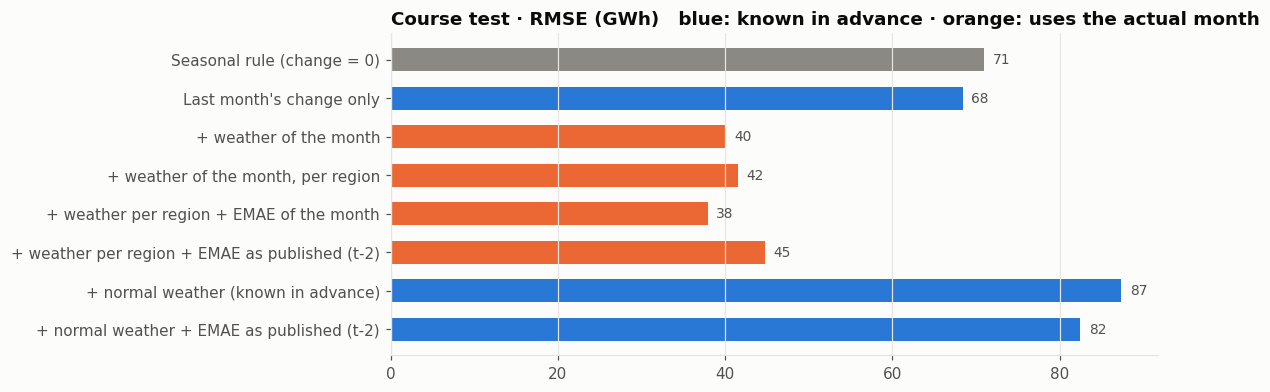

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
v = e.set_index('model')['test RMSE']
colors = [RULE if 'rule' in n else (BLUE if k else ORANGE) for n, k in zip(e['model'], e['known in advance'])]
ax.barh(range(len(v)), v.values, color=colors, height=0.6)
ax.set_yticks(range(len(v)), v.index); ax.invert_yaxis(); ax.grid(axis='x'); ax.grid(axis='y', visible=False)
for i, val in enumerate(v.values): ax.text(val + 1, i, f'{val:.0f}', va='center', fontsize=9, color=INK2)
ax.set_title('Course test · RMSE (GWh)   blue: known in advance · orange: uses the actual month')
fig.savefig(FIG + 'fig04_explore.png'); plt.show()

The actual weather of the month cuts the error by 44 %. Replacing it with the normal weather for that month — what is known when forecasting — loses the gain: **the missing information is the weather itself.**

## What explains the 2018–2019 drop?

A descriptive linear model on every region-month splits each period's change into contributions (weighted by region size).

In [4]:
d0, c0 = x.decomposition()
print({k: round(v, 4) for k, v in c0.items()})
d0.round(1)

{'heating (cold)': 0.001, 'cooling (heat)': 0.0016, 'activity (EMAE)': 0.394, 'R2': 0.5104}


,period,actual change,heating (cold),cooling (heat),activity (EMAE),rest
0,Drop (Sep 2018 - Aug 2019),-6.4,-0.8,-2.2,-1.5,-1.8
1,Recovery (Sep 2019 - Feb 2020),3.2,0.8,2.1,-0.5,1.0


In [5]:
x.tariff_lags().round(3)

,lag (months),region-months,from,tariff coefficient,R2 without,R2 with
0,0,234,2018-01,-2.3e-02,0.5,0.5
1,3,216,2018-03,-1.6e-02,0.5,0.5
2,6,189,2018-06,-1.5e-01,0.5,0.5
3,9,162,2018-09,-2.6e-01,0.4,0.5
4,12,135,2018-12,-2.9e-01,0.4,0.5


Tariffs show no same-month effect, but with a 6–12 month lag a 10 % real increase is followed by 1.5–3 % less demand. With a 6-month lag:

In [6]:
d6, c6 = x.decomposition(tariff_lag=6)
d6.round(1)

,period,actual change,heating (cold),cooling (heat),activity (EMAE),real tariff,rest
0,Drop (Sep 2018 - Aug 2019),-6.4,-1.0,-2.0,-0.6,-1.5,-1.5
1,Recovery (Sep 2019 - Feb 2020),3.2,0.9,1.9,-0.2,0.1,0.3


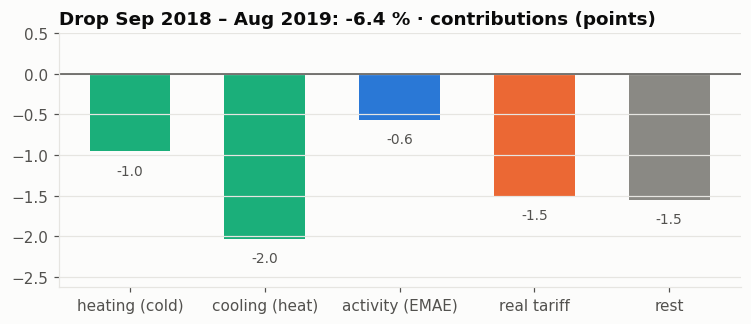

In [7]:
row = d6.iloc[0]
parts = ['heating (cold)', 'cooling (heat)', 'activity (EMAE)', 'real tariff', 'rest']
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(len(parts)), [row[p] for p in parts], color=[AQUA, AQUA, BLUE, ORANGE, RULE], width=0.6)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(range(len(parts)), parts)
for i, p in enumerate(parts): ax.text(i, row[p] - 0.15, f'{row[p]:.1f}', ha='center', va='top', fontsize=9, color=INK2)
ax.set_title(f"Drop Sep 2018 – Aug 2019: {row['actual change']:.1f} % · contributions (points)")
ax.set_ylim(min(row[p] for p in parts) - 0.6, 0.5)
fig.savefig(FIG + 'fig05_drop.png'); plt.show()

**Takeaways**

- About half of the drop was weather (milder summers and a warm 2019 winter); recession and tariffs together about a third; the rest includes one-off cases such as the Alumbrera mine (≈ 0.5 points).
- Activity and tariffs moved together in 2018–2019, so the split *between them* is unstable; their joint ≈ −2 points is the robust part.
- The recovery in the course test was almost all weather, while activity was still falling.